# z001 - Exploración del dataset

**Objetivo:** entender qué hay en `competencia_01.csv` antes de modelar.

Preguntas que queremos responder:
1. ¿Qué meses hay y cuáles tienen el target (`clase_ternaria`)?
2. ¿Cuántas bajas hay por mes? (desbalance)
3. ¿Hay variables vacías o rotas en algún mes? (drift, clase 7)
4. ¿Qué variables separan a los que se van de los que se quedan?

Corré las celdas **de a una** y anotá lo que ves al final.

In [1]:
# --- 1. Librerías y carga de datos ---
import pandas as pd               # tablas de datos
import matplotlib.pyplot as plt   # gráficos

# El archivo está una carpeta arriba (en py/), por eso el "../"
df = pd.read_csv("../competencia_01.csv")

# Cuántas filas (clientes-mes) y columnas (variables) hay
print("Filas, columnas:", df.shape)
df.head()

Filas, columnas: (983061, 155)


,numero_de_cliente,foto_mes,active_quarter,cliente_vip,internet,cliente_edad,cliente_antiguedad,mrentabilidad,mrentabilidad_annual,mcomisiones,...,Visa_fultimo_cierre,Visa_mpagado,Visa_mpagospesos,Visa_mpagosdolares,Visa_fechaalta,Visa_mconsumototal,Visa_cconsumos,Visa_cadelantosefectivo,Visa_mpagominimo,clase_ternaria
0,40262915,202103,1,0,0,60,151,4320.95,27730.93,576.44,...,1.0,0.00,-3936.45,0.00,4572.0,21075.53,10.0,0.0,1114.35,CONTINUA
1,40262915,202104,1,0,0,60,152,3121.71,30452.79,440.39,...,2.0,0.00,-22962.60,23.72,4602.0,18167.30,8.0,0.0,1137.81,CONTINUA
2,40262915,202105,1,0,0,60,153,2575.74,32558.82,459.32,...,5.0,25396.72,-20165.72,0.00,4633.0,22758.35,10.0,0.0,1958.91,CONTINUA
3,40262915,202106,1,0,0,60,154,5927.84,38119.06,4562.94,...,0.0,25458.13,-25408.41,9.48,4663.0,35436.65,14.0,0.0,4996.98,CONTINUA
4,40262915,202107,1,0,0,60,155,5897.02,43515.53,4065.48,...,3.0,0.00,-42600.22,43.88,4694.0,23126.17,11.0,0.0,3120.18,NaN


In [2]:
# --- 2. ¿Qué meses hay? ---
# value_counts cuenta cuántas filas hay por cada mes; sort_index los ordena
df["foto_mes"].value_counts().sort_index()

foto_mes
202103    162900
202104    163284
202105    163768
202106    164114
202107    164348
202108    164647
Name: count, dtype: int64

In [3]:
# --- 3. Target por mes ---
# crosstab arma una tabla: filas = meses, columnas = clases.
# fillna reemplaza los vacíos por "SIN_TARGET" para que también se cuenten.
tabla = pd.crosstab(df["foto_mes"], df["clase_ternaria"].fillna("SIN_TARGET"))
tabla

clase_ternaria,BAJA+1,BAJA+2,CONTINUA,SIN_TARGET
foto_mes,,,,
202103,1018,953,160929,0
202104,957,1135,161192,0
202105,1139,867,161762,0
202106,871,1098,162145,0
202107,1103,0,0,163245
202108,0,0,0,164647


In [4]:
# --- 4. Porcentaje de bajas por mes (desbalance) ---
# Dividimos cada fila por su total y multiplicamos por 100
(tabla.div(tabla.sum(axis=1), axis=0) * 100).round(2)

clase_ternaria,BAJA+1,BAJA+2,CONTINUA,SIN_TARGET
foto_mes,,,,
202103,0.62,0.59,98.79,0.00
202104,0.59,0.70,98.72,0.00
202105,0.70,0.53,98.78,0.00
202106,0.53,0.67,98.80,0.00
202107,0.67,0.00,0.00,99.33
202108,0.00,0.00,0.00,100.00


In [5]:
# --- 5. Valores faltantes por variable ---
# isna() marca True donde falta el dato; mean() da la proporción de faltantes
faltantes = (df.isna().mean() * 100).sort_values(ascending=False)

# Mostramos solo las que tienen algún faltante
faltantes[faltantes > 0].round(1)

Master_Finiciomora             99.5
Visa_Finiciomora               98.6
Master_mpagospesos             58.9
Master_mconsumosdolares        58.9
Master_cconsumos               58.9
Master_mconsumototal           58.9
Master_mconsumospesos          58.9
Master_mpagosdolares           58.9
Master_madelantodolares        58.9
Master_madelantopesos          58.9
Master_cadelantosefectivo      58.9
clase_ternaria                 33.4
Visa_mconsumototal             13.0
Visa_mpagospesos               13.0
Visa_madelantopesos            13.0
Visa_cconsumos                 13.0
Visa_mconsumospesos            13.0
Visa_madelantodolares          13.0
Visa_mconsumosdolares          13.0
Visa_mpagosdolares             13.0
Visa_cadelantosefectivo        13.0
Master_fultimo_cierre          10.2
Master_status                  10.1
Master_mpagado                 10.1
Master_mpagominimo             10.1
Master_delinquency             10.1
Master_mfinanciacion_limite    10.1
Master_fechaalta            

In [6]:
# --- 6. Variables rotas: todo cero o todo vacío en algún mes ---
# Si una variable vale 0 para TODOS los clientes en un mes, casi seguro
# es un error de carga de ese mes (no que nadie la usó).

# Columnas numéricas que no son el ID, el mes ni el target
variables = [c for c in df.columns
             if c not in ["numero_de_cliente", "foto_mes", "clase_ternaria"]]

# Para cada mes: proporción de ceros y de vacíos en cada variable
prop_ceros  = df.groupby("foto_mes")[variables].agg(lambda x: (x == 0).mean())
prop_vacios = df.groupby("foto_mes")[variables].agg(lambda x: x.isna().mean())

# Buscamos combinaciones (mes, variable) que estén 100% en cero o 100% vacías
rotas = []
for mes in prop_ceros.index:
    for var in variables:
        if prop_ceros.loc[mes, var] == 1 or prop_vacios.loc[mes, var] == 1:
            rotas.append((mes, var))

print("Combinaciones mes-variable rotas:", len(rotas))
pd.DataFrame(rotas, columns=["foto_mes", "variable"])

Combinaciones mes-variable rotas: 1


,foto_mes,variable
0,202105,ccajas_depositos


Variables del top 40 presentes en el CSV: 37


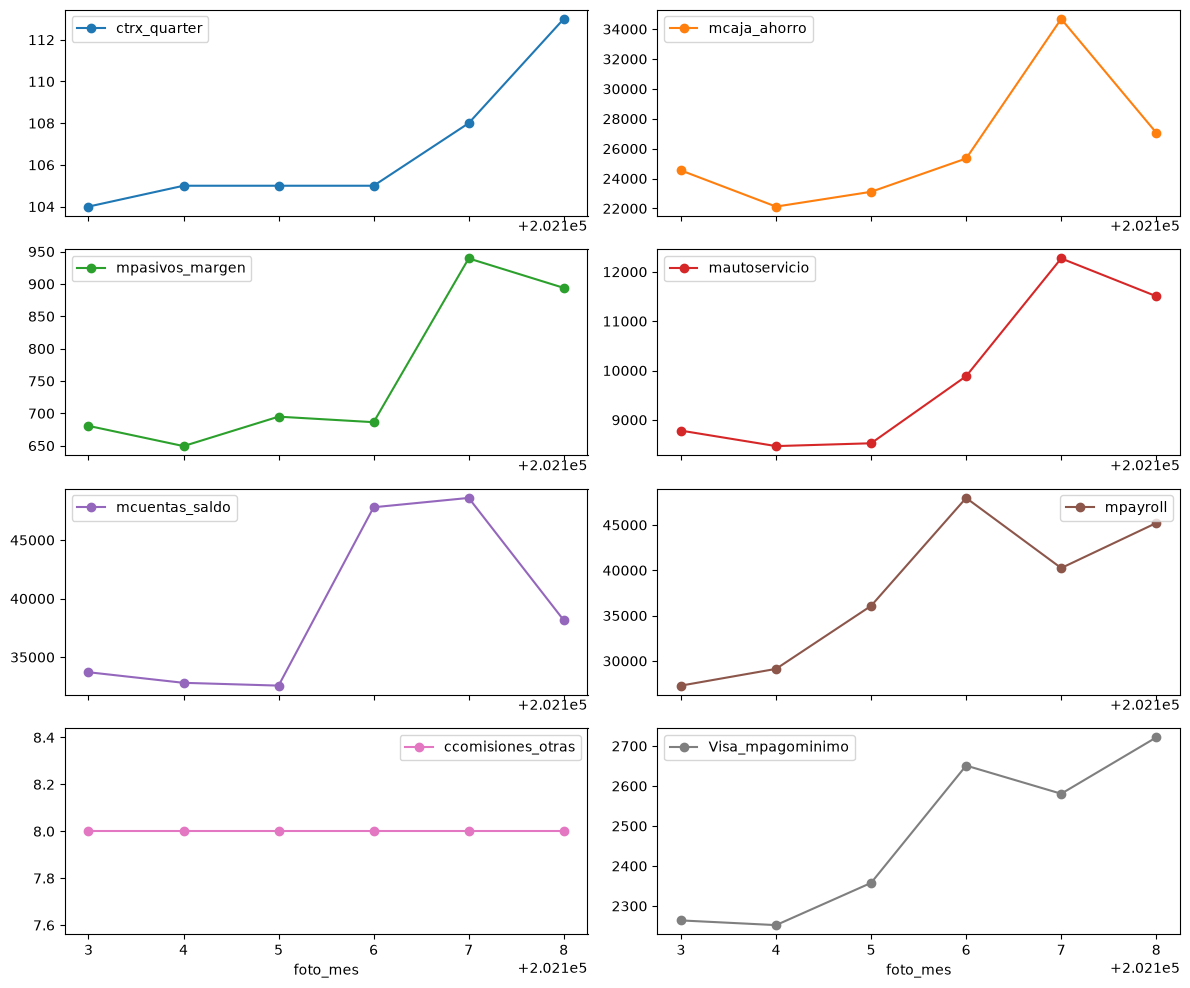

In [7]:
# --- 7. Drift: ¿cambian mucho las variables entre meses? ---
# Leemos el top 40 que seleccionaste en la clase 5
with open("../clusters/variables_seleccionadas.txt") as f:
    top40 = [linea.strip() for linea in f
             if linea.strip() and not linea.startswith("#")]

# Nos quedamos con las que existen en el dataset original
# (las "_delta1" las habías creado vos, no están en el CSV)
top40 = [v for v in top40 if v in df.columns]
print("Variables del top 40 presentes en el CSV:", len(top40))

# Mediana de cada variable por mes. Si un monto crece mes a mes
# (por ejemplo, por inflación), es drift.
medianas = df.groupby("foto_mes")[top40[:8]].median()

# Un gráfico chico por variable
medianas.plot(subplots=True, layout=(4, 2), figsize=(12, 10), marker="o")
plt.tight_layout()
plt.show()

In [8]:
# --- 8. Relevancia: tasa de baja por decil ---
# Idea: dividimos una variable en 10 grupos (de menor a mayor) y vemos
# qué porcentaje de BAJA+2 hay en cada grupo. Si cambia mucho, la variable importa.

# Elegí un mes CON target (mirá la celda 3). Cambialo si hace falta.
MES = 202104
datos_mes = df[df["foto_mes"] == MES].copy()
datos_mes["es_baja"] = (datos_mes["clase_ternaria"] == "BAJA+2").astype(int)

def tasa_por_decil(variable):
    # qcut parte en 10 grupos con la misma cantidad de clientes.
    # duplicates="drop" evita errores cuando hay muchos valores repetidos (ej: muchos ceros)
    grupos = pd.qcut(datos_mes[variable], 10, duplicates="drop")
    return datos_mes.groupby(grupos, observed=True)["es_baja"].mean() * 100

# Probamos con la primera variable del top 40
tasa_por_decil(top40[0]).round(2)

ctrx_quarter
(-0.001, 27.0]     4.21
(27.0, 49.0]       1.12
(49.0, 69.0]       0.50
(69.0, 87.0]       0.33
(87.0, 105.0]      0.23
(105.0, 124.0]     0.12
(124.0, 146.0]     0.10
(146.0, 174.0]     0.10
(174.0, 221.0]     0.10
(221.0, 3437.0]    0.08
Name: es_baja, dtype: float64

In [9]:
# --- 9. Ranking simple: qué tanto separa cada variable ---
# Para cada variable: tasa de baja del decil más alto menos la del más bajo.
# Cuanto más grande la diferencia (en valor absoluto), más separa.
resultado = []
for var in top40:
    try:
        tasas = tasa_por_decil(var)
        resultado.append((var, tasas.max() - tasas.min()))
    except Exception as e:
        # Si una variable no se puede partir (ej: casi toda vacía), la salteamos
        print("No se pudo con", var, "->", e)

ranking = pd.DataFrame(resultado, columns=["variable", "rango_tasa_baja"])
ranking.sort_values("rango_tasa_baja", ascending=False).head(20)

,variable,rango_tasa_baja
0,ctrx_quarter,4.134100
1,mcaja_ahorro,3.625218
2,mpasivos_margen,3.116946
6,ccomisiones_otras,2.774499
4,mcuentas_saldo,2.235287
3,mautoservicio,1.714737
17,chomebanking_transacciones,1.637175
13,mactivos_margen,1.604606
23,mcuenta_corriente,1.595744
19,cproductos,1.554402


## Conclusiones (completar después de correr)

- Meses disponibles: ...
- Meses con target completo: ...
- % de BAJA+2 por mes: ...
- Variables rotas (mes, variable): ...
- Variables con drift fuerte: ...
- Variables que más separan: ...